# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: C:\Users\kemo7\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

### Solution

#### 1. Load `bert-base-uncased` and print the number of layers and attention heads

In [6]:
from transformers import AutoTokenizer, AutoModel
import torch

bert_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)

# "eager" attention is needed to get the attention weights back from the model
bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval()

# BERT stores these values under different names than DistilBERT (n_layers, n_heads)
num_layers = bert_model.config.num_hidden_layers
num_heads = bert_model.config.num_attention_heads

print("Transformer layers:", num_layers)
print("Attention heads per layer:", num_heads)
print("Hidden size:", bert_model.config.hidden_size)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Transformer layers: 12
Attention heads per layer: 12
Hidden size: 768


**Result:** `bert-base-uncased` has **12 Transformer layers** with **12 attention heads** in each layer (hidden size 768). This is twice the depth of DistilBERT, which has only 6 layers.

*Note:* the "UNEXPECTED" keys in the load report are the weights of BERT's pre-training heads (`cls.predictions`, `cls.seq_relationship`). `AutoModel` loads only the base Transformer, so these weights are not needed and can be ignored.

#### 2. Total number of attention heads across all layers

Every layer has its own attention heads, so the total is **layers × heads per layer**.

In [7]:
total_heads = num_layers * num_heads

print(f"Total attention heads: {num_layers} layers x {num_heads} heads = {total_heads}")

Total attention heads: 12 layers x 12 heads = 144


#### 3. Attention weights of the third layer and second head

Python counts from 0, so the **third layer** is index `2` and the **second head** is index `1`.

`outputs.attentions` is a tuple with one tensor per layer. Each tensor has the shape *(batch, heads, tokens, tokens)*.

In [8]:
task_sentence = "Transformers use self-attention to understand language."

task_inputs = bert_tokenizer(task_sentence, return_tensors="pt")
task_tokens = bert_tokenizer.convert_ids_to_tokens(task_inputs["input_ids"][0])

with torch.no_grad():
    task_outputs = bert_model(**task_inputs, output_attentions=True)

print("Tokens:", task_tokens)
print("Number of layers in outputs.attentions:", len(task_outputs.attentions))
print("Shape of one layer:", task_outputs.attentions[2].shape, "-> (batch, heads, tokens, tokens)")

# Third layer (index 2), first sentence in the batch (index 0), second head (index 1)
layer3_head2 = task_outputs.attentions[2][0, 1]

print()
print("Attention shape (layer 3, head 2):", layer3_head2.shape)

Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Number of layers in outputs.attentions: 12
Shape of one layer: torch.Size([1, 12, 11, 11]) -> (batch, heads, tokens, tokens)

Attention shape (layer 3, head 2): torch.Size([11, 11])


In [9]:
import pandas as pd

# Show the matrix as a table with the tokens as row and column names
attention_table = pd.DataFrame(layer3_head2.numpy(), index=task_tokens, columns=task_tokens).round(3)
attention_table

,[CLS],transformers,use,self,-,attention,to,understand,language,.,[SEP]
[CLS],0.732,0.008,0.011,0.006,0.017,0.007,0.010,0.012,0.006,0.039,0.155
transformers,0.889,0.005,0.034,0.000,0.003,0.005,0.001,0.001,0.000,0.005,0.057
use,0.143,0.569,0.005,0.035,0.041,0.068,0.090,0.000,0.005,0.009,0.034
self,0.340,0.073,0.002,0.000,0.202,0.081,0.064,0.026,0.002,0.028,0.183
-,0.143,0.070,0.071,0.639,0.012,0.013,0.003,0.003,0.014,0.009,0.022
attention,0.113,0.545,0.012,0.020,0.111,0.010,0.072,0.000,0.000,0.016,0.100
to,0.084,0.022,0.622,0.008,0.009,0.194,0.011,0.007,0.001,0.014,0.027
understand,0.434,0.005,0.002,0.022,0.012,0.003,0.330,0.002,0.055,0.053,0.082
language,0.051,0.001,0.429,0.002,0.004,0.001,0.005,0.398,0.006,0.041,0.062
.,0.658,0.006,0.003,0.001,0.004,0.003,0.009,0.038,0.046,0.073,0.159


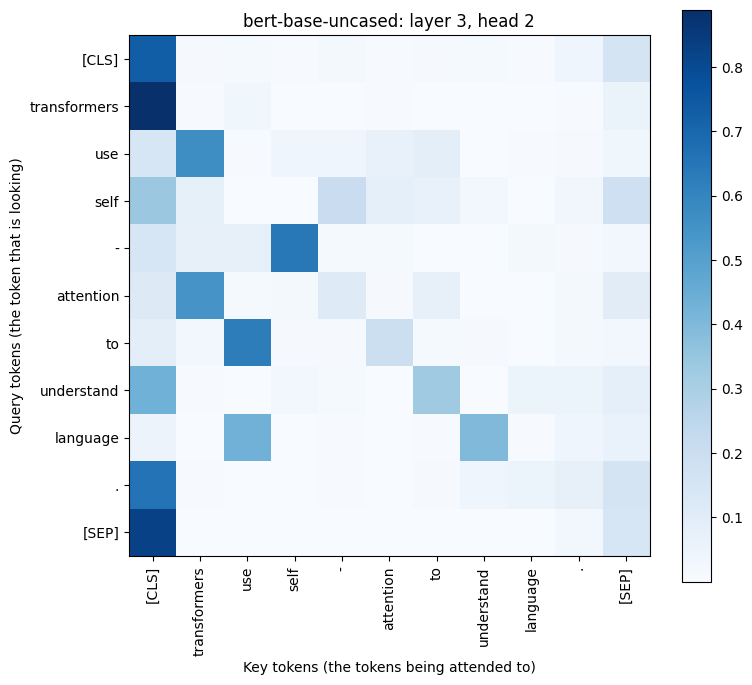

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(layer3_head2, cmap="Blues")

ax.set_xticks(range(len(task_tokens)))
ax.set_yticks(range(len(task_tokens)))
ax.set_xticklabels(task_tokens, rotation=90)
ax.set_yticklabels(task_tokens)
ax.set_xlabel("Key tokens (the tokens being attended to)")
ax.set_ylabel("Query tokens (the token that is looking)")
ax.set_title("bert-base-uncased: layer 3, head 2")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [11]:
# Each row is a probability distribution (softmax), so every row sums to 1
print("Sum of each row:", layer3_head2.sum(dim=1).round(decimals=3))

# The token that each token attends to the most
print()
for token, row in zip(task_tokens, layer3_head2):
    best = row.argmax().item()
    print(f"{token:>12} -> {task_tokens[best]:<12} ({row[best]:.2f})")

Sum of each row: tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

       [CLS] -> [CLS]        (0.73)
transformers -> [CLS]        (0.89)
         use -> transformers (0.57)
        self -> [CLS]        (0.34)
           - -> self         (0.64)
   attention -> transformers (0.54)
          to -> use          (0.62)
  understand -> [CLS]        (0.43)
    language -> use          (0.43)
           . -> [CLS]        (0.66)
       [SEP] -> [CLS]        (0.83)


**Result:** The sentence is split into **11 tokens**: `[CLS]`, 9 word tokens (*self-attention* becomes 3 tokens: `self`, `-`, `attention`) and `[SEP]`. So the attention matrix of layer 3, head 2 has the shape **11 × 11**.

#### 4. What do the rows and columns of the attention matrix represent?

- **Rows = query tokens.** Row *i* belongs to token *i* and shows **how much this token pays attention to each token** of the sentence when the model builds its new (contextual) vector.
- **Columns = key tokens.** Column *j* belongs to token *j*, the token that **is being attended to**. Reading down a column shows how much every token looks at token *j*.
- **Each value** `attention[i][j]` is the weight that token *i* gives to token *j*. The new vector of token *i* is the weighted sum of the (value) vectors of all tokens with these weights.
- The weights come from a **softmax**, so all values are between 0 and 1 and **every row sums to 1** (shown above). The columns do **not** have to sum to 1.
- The matrix is **square** (tokens × tokens) because in *self*-attention the sentence attends to itself, and it is **not symmetric**: how much *use* looks at *transformers* (0.57) is different from how much *transformers* looks at *use* (0.03).
- It includes the special tokens `[CLS]` and `[SEP]` and the sub-word tokens, because attention works on tokens, not on words.

**What this head (layer 3, head 2) does in our sentence:**

- Many tokens attend mostly to the **previous token**: *use → transformers* (0.57), *- → self* (0.64), *to → use* (0.62), *understand → to* (0.33). This head works like a "look at the word before me" head.
- Some links follow the meaning of the sentence: *attention → transformers* (0.54) and *language → use* (0.43) / *understand* (0.40), which connects the object *language* with its verbs.
- Tokens that do not need information from other tokens put most of their weight on **`[CLS]`** (*transformers* 0.89, *[SEP]* 0.83, *.* 0.66). In BERT, attending to `[CLS]`/`[SEP]` is often a "no-operation": the head has nothing useful to add for that token.

Each of the 144 heads learns a different pattern, so this is only one of many views of the sentence.

__________________________________________________________________________________________

# What I Learned from Lab 12

In this lab I learned how a **Transformer** processes text with **self-attention**, and how to look inside a pretrained model with Hugging Face Transformers.

### From text to prediction (DistilBERT)
- The **tokenizer** converts the sentence into token IDs and adds the special tokens `[CLS]` (start) and `[SEP]` (end).
- Each token ID becomes an **embedding** vector (size 768). The Transformer layers turn these vectors into **contextual** vectors, where each token also contains information from the other tokens.
- The **classification head** produces two scores (*logits*) and **softmax** converts them into probabilities. *"The movie was not good."* was predicted **NEGATIVE** with confidence 1.0, so the model understood that *not* changes the meaning of *good*.

### Layers and attention heads (BERT)
- `bert-base-uncased` has **12 layers × 12 heads = 144 attention heads**, while DistilBERT has 6 layers × 12 heads = 72.
- The two models use different config names: `num_hidden_layers` / `num_attention_heads` in BERT and `n_layers` / `n_heads` in DistilBERT.
- To get the attention weights, the model must use `attn_implementation="eager"` and be called with `output_attentions=True`. The result has one tensor per layer with the shape *(batch, heads, tokens, tokens)*, and Python indexing starts at 0 (third layer = `2`, second head = `1`).

### The attention matrix
- Rows are the tokens that are looking (queries), columns are the tokens being looked at (keys), and every row sums to 1 because of softmax.
- The matrix is square and not symmetric.
- Layer 3, head 2 mostly looks at the previous token and at `[CLS]`, and it also links some related words (*language → use / understand*). Different heads learn different patterns, and together they help the model understand the sentence.